Clone the Repositroy in the Notebook Accessible Path

In [ ]:
# Need to Clone for every Fresh Runtime Session in Colab
!git clone https://github.com/Dgowda11/llama-spam-finetuning.git /content/repo-clone

In [ ]:
# Set Base path and Pull the Recent Changes from the repo to colab
from pathlib import Path
import os

PROJECT_ROOT = Path("/content/repo-clone")

print("Exists:", PROJECT_ROOT.exists())
print("Is directory:", PROJECT_ROOT.is_dir())
print("Git metadata exists:", (PROJECT_ROOT / ".git").exists())

print("\nContents of /content:")
print(os.listdir("/content"))

print("\nRepository directory contents:")
if PROJECT_ROOT.exists():
    print(os.listdir(PROJECT_ROOT))

%cd /content/repo-clone
!git status
!git pull origin main

 Install Kaggle CLI

In [3]:
%pip install -q kaggle

In [ ]:
# Download dataset directly from Kaggle
!kaggle datasets download -d uciml/sms-spam-collection-dataset \
    -p /content/llama-spam-finetuning/data/raw \
    --unzip

In [5]:
#Verify the Downloaded Files 
import os

dataset_dir = "/content/llama-spam-finetuning/data/raw"

print(os.listdir(dataset_dir))

['spam.csv']


Kaggle Dataset → Colab Runtime → DatasetLoader → DataAnalyzer

In [6]:
from src.data.dataset_loader import DatasetLoader

dataset_path = os.path.join(dataset_dir, "spam.csv")
dataset_loader = DatasetLoader(dataset_path)
dataset = dataset_loader.load()

Dataset Structure Analysis

In [14]:
df = dataset
print(type(df))
df.shape


<class 'pandas.core.frame.DataFrame'>


(5572, 5)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [9]:
df.columns.to_list()

['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

In [10]:
df.head(10)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


In [11]:
df.describe(include='all')

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2


Investigate the malformed CSV records

In [15]:
#Display records with extra-column values
extra_columns = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

df[df[extra_columns].notna().any(axis=1)].head(15)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
95,spam,Your free ringtone is waiting to be collected....,PO Box 5249,"MK17 92H. 450Ppw 16""",NaN
281,ham,\Wen u miss someone,the person is definitely special for u..... B...,why to miss them,"just Keep-in-touch\"" gdeve.."""
444,ham,\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAR...,HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE ...,NaN,NaN
671,spam,SMS. ac sun0819 posts HELLO:\You seem cool,"wanted to say hi. HI!!!\"" Stop? Send STOP to ...",NaN,NaN
710,ham,Height of Confidence: All the Aeronautics prof...,"this wont even start........ Datz confidence..""",NaN,NaN
899,spam,Your free ringtone is waiting to be collected....,PO Box 5249,"MK17 92H. 450Ppw 16""",NaN
1038,ham,"Edison has rightly said, \A fool can ask more ...",GN,GE,"GNT:-)"""
1127,ham,"Height of \Oh shit....!!\"" situation: A guy th...",".;-):-D""",NaN,NaN
1266,ham,\Hey sorry I didntgive ya a a bellearlier hunny,just been in bedbut mite go 2 thepub l8tr if u...,NaN,NaN
1384,ham,"Storming msg: Wen u lift d phne, u say \HELLO\...","bt not his girlfrnd... G o o d n i g h t . . .@""",NaN,NaN


In [16]:
#2. Count records with extra-column content
df[extra_columns].notna().any(axis=1).sum()

np.int64(50)

Let's Preserve the Malformed Recrods since it is Msg Continuos 

In [17]:
extra_columns = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

df["message"] = (
    df[["v2"] + extra_columns]
    .fillna("")
    .astype(str)
    .agg(",".join, axis=1)
    .str.rstrip(",")
)

df["label"] = df["v1"]

In [18]:
df.loc[
    df[extra_columns].notna().any(axis=1),
    ["v1", "v2", "message"]
].head(10)

,v1,v2,message
95,spam,Your free ringtone is waiting to be collected....,Your free ringtone is waiting to be collected....
281,ham,\Wen u miss someone,"\Wen u miss someone, the person is definitely ..."
444,ham,\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAR...,\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAR...
671,spam,SMS. ac sun0819 posts HELLO:\You seem cool,"SMS. ac sun0819 posts HELLO:\You seem cool, wa..."
710,ham,Height of Confidence: All the Aeronautics prof...,Height of Confidence: All the Aeronautics prof...
899,spam,Your free ringtone is waiting to be collected....,Your free ringtone is waiting to be collected....
1038,ham,"Edison has rightly said, \A fool can ask more ...","Edison has rightly said, \A fool can ask more ..."
1127,ham,"Height of \Oh shit....!!\"" situation: A guy th...","Height of \Oh shit....!!\"" situation: A guy th..."
1266,ham,\Hey sorry I didntgive ya a a bellearlier hunny,\Hey sorry I didntgive ya a a bellearlier hunn...
1384,ham,"Storming msg: Wen u lift d phne, u say \HELLO\...","Storming msg: Wen u lift d phne, u say \HELLO\..."


1.Analyze Ham vs Spam distribution

In [19]:
df["label"].value_counts()

,count
label,
ham,4825
spam,747


In [20]:
df["label"].value_counts(normalize=True) * 100

,proportion
label,
ham,86.593683
spam,13.406317


2. Visualize class distribution

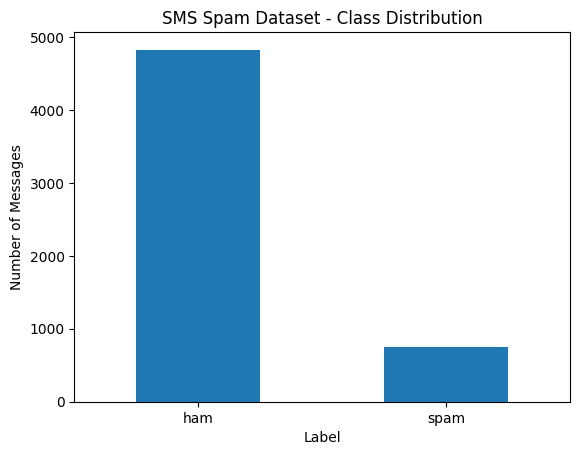

In [21]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar")

plt.title("SMS Spam Dataset - Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

Duplicate Data Analysis

In [25]:
df["message"].duplicated().sum()

np.int64(403)

In [27]:
# Count the Unique Messages
df["message"].nunique()

5169

Inspect duplicate records & Check weather the Duplicated Records have Conflicting Labels

In [28]:
duplicates = df[df["message"].duplicated(keep=False)]
duplicates.sort_values(by="message").head(10)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4,message,label
504,spam,+123 Congratulations - in this week's competit...,NaN,NaN,NaN,+123 Congratulations - in this week's competit...,spam
2123,spam,+123 Congratulations - in this week's competit...,NaN,NaN,NaN,+123 Congratulations - in this week's competit...,spam
2343,ham,1) Go to write msg 2) Put on Dictionary mode 3...,NaN,NaN,NaN,1) Go to write msg 2) Put on Dictionary mode 3...,ham
1372,ham,1) Go to write msg 2) Put on Dictionary mode 3...,NaN,NaN,NaN,1) Go to write msg 2) Put on Dictionary mode 3...,ham
2162,ham,1) Go to write msg 2) Put on Dictionary mode 3...,NaN,NaN,NaN,1) Go to write msg 2) Put on Dictionary mode 3...,ham
1049,spam,18 days to Euro2004 kickoff! U will be kept in...,NaN,NaN,NaN,18 days to Euro2004 kickoff! U will be kept in...,spam
2718,spam,18 days to Euro2004 kickoff! U will be kept in...,NaN,NaN,NaN,18 days to Euro2004 kickoff! U will be kept in...,spam
2043,spam,4mths half price Orange line rental & latest c...,NaN,NaN,NaN,4mths half price Orange line rental & latest c...,spam
388,spam,4mths half price Orange line rental & latest c...,NaN,NaN,NaN,4mths half price Orange line rental & latest c...,spam
1778,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...,NaN,NaN,NaN,7 wonders in My WORLD 7th You 6th Ur style 5th...,ham


In [29]:
#Check whether duplicate messages have conflicting labels
label_counts = df.groupby("message")["label"].nunique()

conflicting_messages = label_counts[label_counts > 1]

conflicting_messages

,label
message,


Message Length Analysis

In [ ]:
# 1. Calculate message lengths
df["message_length"] = df["message"].str.len()

In [31]:
# 2. Statistical summary
df["message_length"].describe()

,message_length
count,5572.000000
mean,80.691134
std,60.007636
min,2.000000
25%,36.000000
50%,62.000000
75%,123.000000
max,910.000000


In [32]:
#3. Compare message length by class 
#This helps us understand whether spam messages tend to be longer than legitimate messages.
df.groupby("label")["message_length"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4825.0,71.639378,58.458080,2.0,33.0,52.0,93.0,910.0
spam,747.0,139.157965,28.981074,13.0,133.0,149.0,158.0,224.0


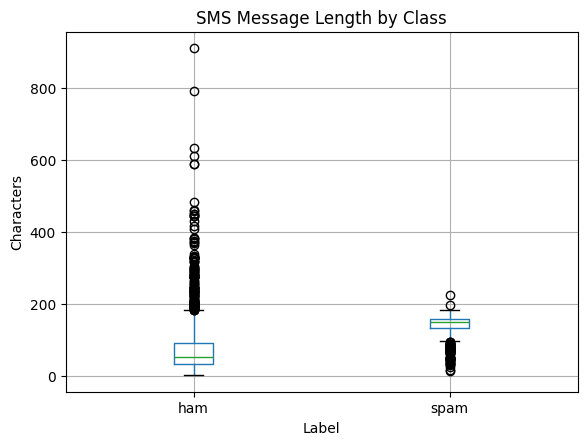

In [33]:
#4. Visualize message lengths
import matplotlib.pyplot as plt

df.boxplot(column="message_length", by="label")

plt.title("SMS Message Length by Class")
plt.suptitle("")
plt.xlabel("Label")
plt.ylabel("Characters")
plt.show()

Dataset Cleaning & Validation.

In [ ]:
#Create the cleaned dataset
clean_df = df[["label", "message"]].copy()

In [35]:
# Step 1.1 – Remove missing values
clean_df = clean_df.dropna(subset=["label", "message"])

In [36]:
# Step 1.2 – Normalize labels
clean_df["label"] = clean_df["label"].str.strip().str.lower()

In [37]:
# Step 1.3 – Remove empty messages
clean_df = clean_df[
    clean_df["message"].str.strip().ne("")
]

In [38]:
# Step 1.4 – Remove duplicate messages
clean_df = clean_df.drop_duplicates(
    subset=["message"],
    keep="first"
)

In [39]:
# Step 1.5 – Reset the index
clean_df = clean_df.reset_index(drop=True)

Step 2 – Validate the cleaned dataset

In [40]:
clean_df.shape

(5169, 2)

In [42]:
# Verify Columns 
clean_df.columns.tolist()

['label', 'message']

In [43]:
clean_df.isnull().sum()

,0
label,0
message,0


In [44]:
# Verify Duplicate Messages
clean_df["message"].duplicated().sum()

np.int64(0)

In [45]:
# Verfiy Empty Messages 
clean_df["message"].str.strip().eq("").sum()

np.int64(0)

Step 3 – Final validation summary

In [46]:
print("Dataset Shape:", clean_df.shape)
print("Columns:", clean_df.columns.tolist())
print("Missing Values:", clean_df.isnull().sum().sum())
print("Duplicate Messages:", clean_df["message"].duplicated().sum())
print("Empty Messages:", clean_df["message"].str.strip().eq("").sum())
print("Labels:", clean_df["label"].unique())

Dataset Shape: (5169, 2)
Columns: ['label', 'message']
Missing Values: 0
Duplicate Messages: 0
Empty Messages: 0
Labels: ['ham' 'spam']


Publish the Cleaned Dataset to Kaggle

In [47]:
# First Export the Cleaned Dataset into csv 
from pathlib import Path

KAGGLE_UPLOAD_DIR = Path("/content/kaggle_sms_spam_dataset")
KAGGLE_UPLOAD_DIR.mkdir(parents=True, exist_ok=True)

csv_path = KAGGLE_UPLOAD_DIR / "sms_spam_cleaned.csv"

clean_df.to_csv(csv_path, index=False)

print("Exported:", csv_path)
print("Dataset shape:", clean_df.shape)

Exported: /content/kaggle_sms_spam_dataset/sms_spam_cleaned.csv
Dataset shape: (5169, 2)


In [49]:
#Authenticate Kaggle before upload
import kagglehub

kagglehub.login()

In [51]:
import kagglehub

handle = 'dgowda11/sms-spam-cleaned'
local_dataset_dir = '/content/kaggle_sms_spam_dataset'

# Create a new dataset
kagglehub.dataset_upload(
    handle,
    local_dataset_dir,
    version_notes='Initial upload'
)


Uploading Dataset https://kaggle.com/datasets/dgowda11/sms-spam-cleaned ...
Starting upload for file /content/kaggle_sms_spam_dataset/sms_spam_cleaned.csv


Uploading: 100%|██████████| 442k/442k [00:00<00:00, 2.08MB/s]

Upload successful: /content/kaggle_sms_spam_dataset/sms_spam_cleaned.csv (431KB)


Your dataset has been created.
Files are being processed...
See at: https://kaggle.com/datasets/dgowda11/sms-spam-cleaned
